## F2 Evaluación

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, 
    recall_score, f1_score, roc_auc_score, roc_curve, auc
)

# 1. Cargar y alinear los datos por EmployeeNumber
y_test_df = pd.read_csv('../datos/y_test.csv', index_col='EmployeeNumber')
probs_df = pd.read_csv('../resultados/probabilidades_prueba.csv', index_col='EmployeeNumber')

evaluacion_df = y_test_df.join(probs_df, how='inner')

y_true = evaluacion_df['Attrition']
y_prob = evaluacion_df['Probabilidad_salida']

# 2. Clasificación inicial con umbral 0.5
UMBRAL = 0.5
y_pred = (y_prob >= UMBRAL).astype(int)

# 3. Cálculo de métricas principales
cm = confusion_matrix(y_true, y_pred)
acc = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_prob)

print("=== MATRIZ DE CONFUSIÓN (Umbral 0.5) ===")
print(cm)
print(f"\nExactitud (Accuracy): {acc:.4f}")
print(f"Precisión (Precision): {precision:.4f}")
print(f"Sensibilidad (Recall): {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"Área Bajo la Curva ROC (AUC): {roc_auc:.4f}")

=== MATRIZ DE CONFUSIÓN (Umbral 0.5) ===
[[368   2]
 [ 67   4]]

Exactitud (Accuracy): 0.8435
Precisión (Precision): 0.6667
Sensibilidad (Recall): 0.0563
F1-Score: 0.1039
Área Bajo la Curva ROC (AUC): 0.7724


## Generación de la Curva ROC y Gráfico de Comparación

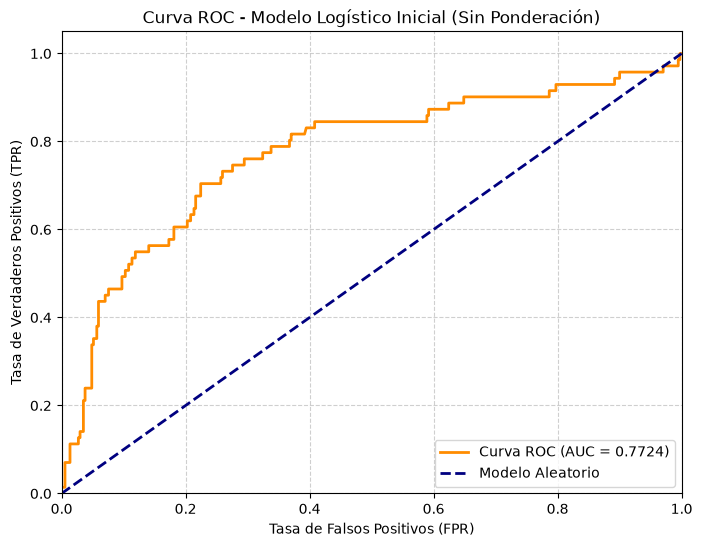

In [2]:
plt.figure(figsize=(8, 6))
fpr, tpr, thresholds = roc_curve(y_true, y_prob)

plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Modelo Aleatorio')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Modelo Logístico Inicial (Sin Ponderación)')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)

# Guardar figura
fig_path = Path('../figuras/curva_roc_evaluacion.png')
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

## Comparación, Análisis de Detecciones y Referencia Base
1. Comparación con la Referencia (Predecir que todos permanecen)
Si se adopta la regla de referencia donde ningún empleado abandona la empresa (y_pred_ref = 0 para todos):

Exactitud de referencia: 370 / 441 = 83.90% (370 permanencias correctas y 71 salidas omitidas).

Exactitud del modelo (umbral 0.5): (368 + 4) / 441 = 84.35%.

Aunque el modelo logístico mejora ligeramente la exactitud global (+0.45%), su verdadera utilidad radica en su capacidad discriminatoria global medida por el AUC de 0.7724, lo que demuestra que el modelo ordena correctamente el riesgo de salida de los empleados por encima del azar.

2. Detalle de Salidas Detectadas y Omitidas (Umbral 0.5)
En el conjunto de prueba hay un total de 71 salidas reales y 370 permanencias reales. Con un umbral de corte estándar de 0.5:

Salidas detectadas (Verdaderos Positivos - TP): El modelo detecta correctamente 4 salidas.

Salidas omitidas (Falsos Negativos - FN): El modelo omite o deja escapar 67 salidas.

Permanencias detectadas correctamente (Verdaderos Negativos - TN): 368 empleados que se quedaban fueron clasificados correctamente.

Falsas alarmas (Falsos Positivos - FP): Solo 2 empleados que permanecían fueron catalogados erróneamente como riesgo de salida.

3. Explicación del Fenómeno
Este comportamiento se debe directamente a la ausencia de ponderación de clases en el modelo logístico inicial ajustado por Lenin. Como la clase minoritaria (salidas) representa solo el 16.13% de los datos, las probabilidades estimadas se concentran por debajo de 0.5 (con una media de 15.96% y un valor máximo de 0.60).

Al usar el umbral estricto de 0.5, el modelo minimiza drásticamente los falsos positivos (solo 2 errores), pero sacrifica severamente la sensibilidad (recall de 5.63%), omitiendo la gran mayoría de las deserciones reales. Esto justifica plenamente la incorporación posterior de ponderación de clases y ajuste de umbrales óptimos (como el estadístico de Youden).